In [33]:
import os
import json
import random
import math
import numpy as np
import matplotlib.pyplot as plt

from glob import glob
from tqdm import tqdm
from PIL import Image
from torch.utils.data import Dataset, DataLoader

import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as T

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"✓ Device: {device}")
if torch.cuda.is_available():
    print(f"  GPU: {torch.cuda.get_device_name(0)}")

✓ Device: cpu


In [34]:
class CBAM(nn.Module):
    """Convolutional Block Attention Module"""
    def __init__(self, channels, reduction=16):
        super().__init__()
        # Channel attention
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(channels // reduction, channels, 1, bias=False)
        )
        # Spatial attention
        self.conv = nn.Conv2d(2, 1, 7, padding=3, bias=False)
        self.sigmoid = nn.Sigmoid()
    
    def forward(self, x):
        # Channel attention
        avg_out = self.fc(self.avg_pool(x))
        max_out = self.fc(self.max_pool(x))
        channel_att = self.sigmoid(avg_out + max_out)
        x = x * channel_att
        
        # Spatial attention
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        spatial_att = self.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))
        x = x * spatial_att
        
        return x

class ResidualBlock(nn.Module):
    """ResNet-style residual block with CBAM"""
    def __init__(self, in_ch, out_ch, stride=1, dilation=1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=dilation, dilation=dilation, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.cbam = CBAM(out_ch)
        
        self.downsample = None
        if stride != 1 or in_ch != out_ch:
            self.downsample = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch)
            )
    
    def forward(self, x):
        identity = x
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = self.cbam(out)
        
        if self.downsample is not None:
            identity = self.downsample(x)
        
        out += identity
        return F.relu(out)

class ASPP(nn.Module):
    """Atrous Spatial Pyramid Pooling"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.convs = nn.ModuleList([
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 1, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU()),
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=6, dilation=6, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU()),
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=12, dilation=12, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU()),
            nn.Sequential(nn.Conv2d(in_ch, out_ch, 3, padding=18, dilation=18, bias=False), nn.BatchNorm2d(out_ch), nn.ReLU())
        ])
        self.global_pool = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(in_ch, out_ch, 1, bias=False),
            nn.ReLU()
        )
        self.project = nn.Sequential(
            nn.Conv2d(out_ch * 5, out_ch, 1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(),
            nn.Dropout(0.5)
        )
    
    def forward(self, x):
        res = [conv(x) for conv in self.convs]
        res.append(F.interpolate(self.global_pool(x), size=x.shape[2:], mode='bilinear', align_corners=False))
        return self.project(torch.cat(res, dim=1))

class DeepLabV3Plus(nn.Module):
    """DeepLabV3+ for 6-channel input (pre + post images)"""
    def __init__(self, num_classes=5):
        super().__init__()
        
        # Encoder
        self.conv1 = nn.Sequential(
            nn.Conv2d(6, 64, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(3, stride=2, padding=1)
        )
        
        self.layer1 = self._make_layer(64, 64, 2)
        self.layer2 = self._make_layer(64, 128, 2, stride=2)
        self.layer3 = self._make_layer(128, 256, 2, stride=2)
        self.layer4 = self._make_layer(256, 512, 2, stride=1, dilation=2)
        
        # ASPP
        self.aspp = ASPP(512, 256)
        
        # Decoder
        self.decoder_conv = nn.Sequential(
            nn.Conv2d(64, 48, 1, bias=False),
            nn.BatchNorm2d(48),
            nn.ReLU()
        )
        
        self.decoder = nn.Sequential(
            nn.Conv2d(304, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Conv2d(256, 256, 3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Dropout(0.1),
            nn.Conv2d(256, num_classes, 1)
        )
    
    def _make_layer(self, in_ch, out_ch, blocks, stride=1, dilation=1):
        layers = [ResidualBlock(in_ch, out_ch, stride, dilation)]
        for _ in range(1, blocks):
            layers.append(ResidualBlock(out_ch, out_ch, dilation=dilation))
        return nn.Sequential(*layers)
    
    def forward(self, x):
        size = x.shape[-2:]
        
        # Encoder
        x = self.conv1(x)
        low_level = self.layer1(x)
        x = self.layer2(low_level)
        x = self.layer3(x)
        x = self.layer4(x)
        
        # ASPP
        x = self.aspp(x)
        
        # Decoder
        low_level = self.decoder_conv(low_level)
        x = F.interpolate(x, size=low_level.shape[2:], mode='bilinear', align_corners=False)
        x = torch.cat([x, low_level], dim=1)
        x = self.decoder(x)
        x = F.interpolate(x, size=size, mode='bilinear', align_corners=False)
        
        return x

model = DeepLabV3Plus(num_classes=5).to(device)
print(f"✓ Model created: {sum(p.numel() for p in model.parameters()):,} parameters")

✓ Model created: 16,700,789 parameters


In [36]:
CHECKPOINT_PATH = "checkpoints/best.pth"

checkpoint = torch.load(CHECKPOINT_PATH, map_location=device)

model.load_state_dict(checkpoint["model_state_dict"])

model = model.to(device)
model.eval()

print("✓ Model loaded from checkpoint")
print("Epoch:", checkpoint["epoch"])

C:\Users\Huawei\AppData\Local\Temp\ipykernel_11668\4242980028.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  checkpoint = torch.load(CHECKPOINT_PATH, map_location=devic

✓ Model loaded from checkpoint
Epoch: 15


In [37]:
CLASS_NAMES = {
    0: "Background",
    1: "No Damage",
    2: "Minor",
    3: "Major",
    4: "Destroyed"
}

CLASS_COLORS = {
    0: [0, 0, 0],       # Black
    1: [0, 255, 0],     # Green
    2: [255, 255, 0],   # Yellow
    3: [255, 165, 0],   # Orange
    4: [255, 0, 0]      # Red
}

NUM_CLASSES = 5

def calculate_iou(pred, target, num_classes=NUM_CLASSES):
    """Calculate IoU per class"""
    ious = []
    pred = pred.cpu().numpy() if isinstance(pred, torch.Tensor) else pred
    target = target.cpu().numpy() if isinstance(target, torch.Tensor) else target
    
    for cls in range(num_classes):
        pred_cls = (pred == cls)
        target_cls = (target == cls)
        
        intersection = np.logical_and(pred_cls, target_cls).sum()
        union = np.logical_or(pred_cls, target_cls).sum()
        
        if union == 0:
            ious.append(float('nan')) 
        else:
            ious.append(intersection / union)
    
    return ious, np.nanmean(ious)

def dice_loss(logits, targets, eps=1e-6):
    """
    Dice Loss that automatically handles any number of classes.
    It ignores index 0 (Background) during calculation.
    """
    # 1. Get number of classes dynamically from logits shape
    num_classes = logits.shape[1]
    
    # 2. Softmax to get probabilities
    probs = torch.softmax(logits, dim=1)
    
    # 3. Slice: Ignore Background (Class 0)
    probs = probs[:, 1:, :, :] 
    
    # 4. Prepare targets (One-hot encoding equivalent)
    targets = targets[:, None, :, :] # Add channel dim
    class_indices = torch.arange(1, num_classes, device=targets.device)[None, :, None, None]
    
    targets = (targets == class_indices).float()

    # 5. Calculate Dice
    intersection = (probs * targets).sum(dim=(2,3))
    union = probs.sum(dim=(2,3)) + targets.sum(dim=(2,3))

    dice = (2 * intersection + eps) / (union + eps)
    return 1 - dice.mean()

def calculate_pixel_accuracy(pred, target):
    """Calculate pixel accuracy"""
    pred = pred.cpu().numpy() if isinstance(pred, torch.Tensor) else pred
    target = target.cpu().numpy() if isinstance(target, torch.Tensor) else target
    return (pred == target).sum() / pred.size

print("✓ Metric functions defined and updated.")

✓ Metric functions defined and updated.


In [38]:
def calc_damage_score(mask):
    """Calculate weighted damage score"""
    DAMAGE_WEIGHTS = {0: 0.0, 1: 0.25, 2: 0.5, 3: 0.75, 4: 1.0}
    if isinstance(mask, torch.Tensor):
        mask = mask.cpu().numpy()
        
    unique, counts = np.unique(mask, return_counts=True)
    weighted = sum(c * DAMAGE_WEIGHTS.get(int(i), 0) for i, c in zip(unique, counts) if i > 0)
    total = sum(c for i, c in zip(unique, counts) if i > 0)
    
    return weighted / total if total > 0 else 0.0

def classify_damage(score):
    """Classify damage level from score"""
    if score < 0.2: return "Background"
    elif score < 0.4: return "No Damage"
    elif score < 0.6: return "Minor Damage"
    elif score < 0.8: return "Major Damage"
    else: return "Complete Destroyed"

def mask_to_rgb(mask):
    """Convert mask to RGB visualization"""
    rgb = np.zeros((*mask.shape, 3), dtype=np.uint8)
    for i, c in CLASS_COLORS.items():
        rgb[mask == i] = c
    return rgb

def visualize_prediction(pre_img, post_img, pred_mask, image_id, save_path=None):
    """Visualize prediction with damage metrics"""
    score = calc_damage_score(pred_mask)
    damage_class = classify_damage(score)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    
    axes[0].imshow(pre_img)
    axes[0].set_title('Pre-Disaster', fontsize=14, fontweight='bold')
    axes[0].axis('off')
    
    axes[1].imshow(post_img)
    axes[1].set_title('Post-Disaster', fontsize=14, fontweight='bold')
    axes[1].axis('off')
    
    axes[2].imshow(mask_to_rgb(pred_mask))
    axes[2].set_title(f'Segmented Damage\nScore: {score:.2%} | {damage_class}', fontsize=14, fontweight='bold')
    axes[2].axis('off')
    
    plt.suptitle(f'Sample: {image_id}', fontsize=16, fontweight='bold')
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    
    return {'score': score, 'percentage': f"{score*100:.2f}%", 'class': damage_class}

print("✓ Visualization functions defined")

✓ Visualization functions defined


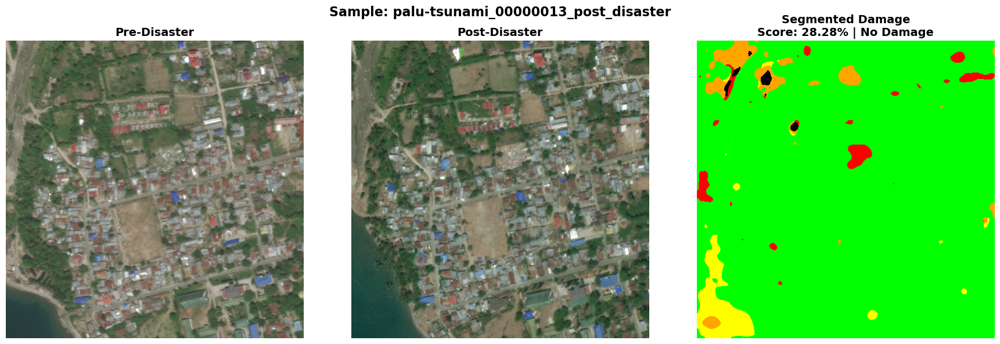

✓ palu-tsunami_00000013_post_disaster: 28.28% - No Damage


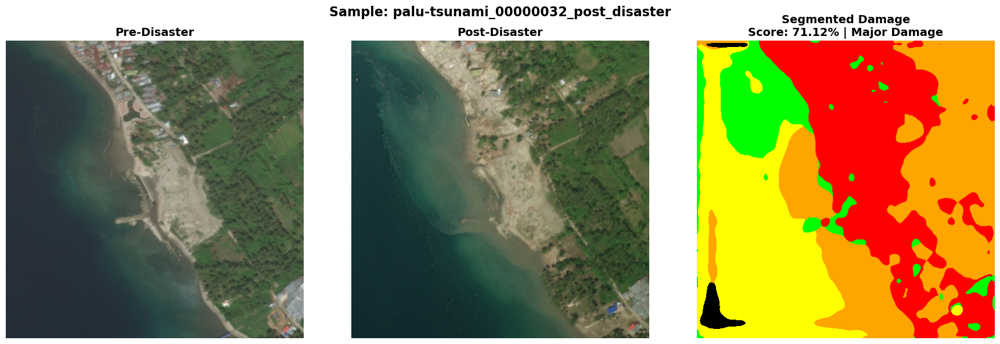

✓ palu-tsunami_00000032_post_disaster: 71.12% - Major Damage


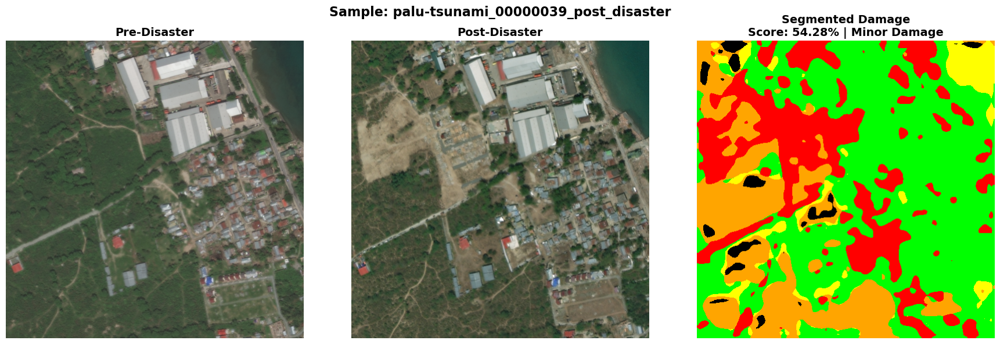

✓ palu-tsunami_00000039_post_disaster: 54.28% - Minor Damage


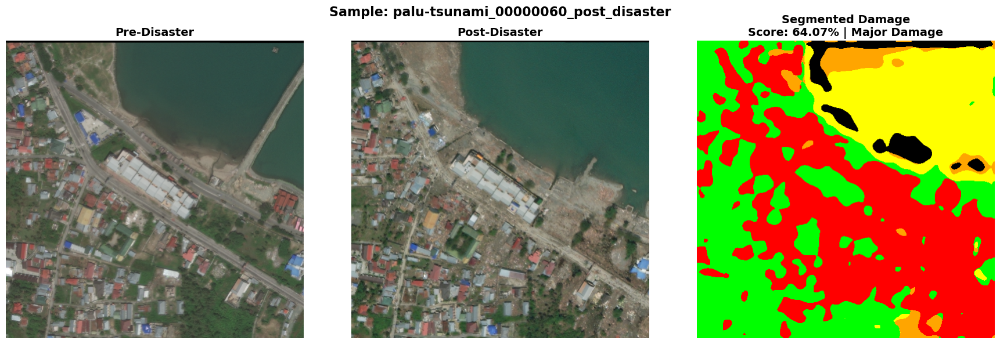

✓ palu-tsunami_00000060_post_disaster: 64.07% - Major Damage


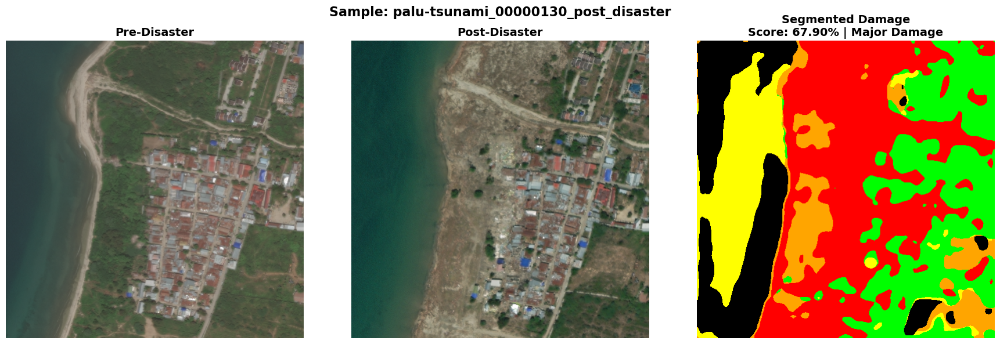

✓ palu-tsunami_00000130_post_disaster: 67.90% - Major Damage


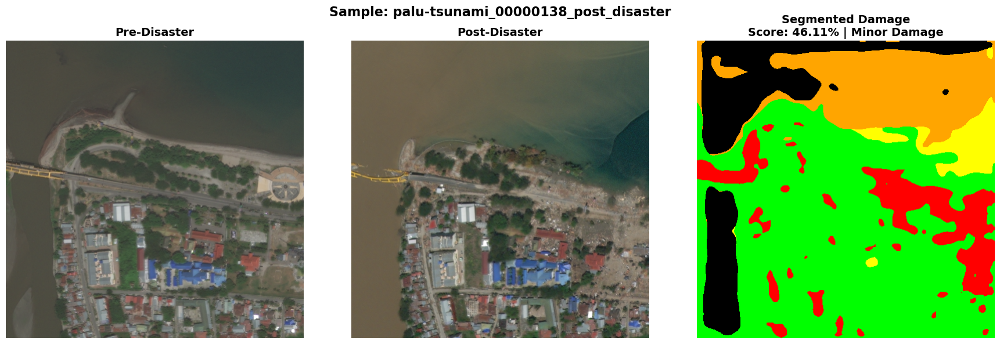

✓ palu-tsunami_00000138_post_disaster: 46.11% - Minor Damage

✓ All predictions saved to: predictions


In [40]:
PRED_DIR = "predictions"
os.makedirs(PRED_DIR, exist_ok=True)

def pred_image(img_path):
    """
    Predict damage mask for one image path from sample_image folder.
    img_path can point to either pre-disaster or post-disaster image.
    """
    img_path = os.path.normpath(img_path)

    if "post-disaster" in img_path:
        post_path = img_path
        pre_dir = os.path.dirname(img_path).replace("post-disaster", "pre-disaster")
        pre_name = os.path.basename(img_path).replace("_post_disaster", "_pre_disaster")
        pre_path = os.path.join(pre_dir, pre_name)
    elif "pre-disaster" in img_path:
        pre_path = img_path
        post_dir = os.path.dirname(img_path).replace("pre-disaster", "post-disaster")
        post_name = os.path.basename(img_path).replace("_pre_disaster", "_post_disaster")
        post_path = os.path.join(post_dir, post_name)
    else:
        raise ValueError("img_path harus berada di folder pre-disaster atau post-disaster")

    if not os.path.exists(pre_path):
        raise FileNotFoundError(f"Pre image tidak ditemukan: {pre_path}")
    if not os.path.exists(post_path):
        raise FileNotFoundError(f"Post image tidak ditemukan: {post_path}")

    pre_img = Image.open(pre_path).convert('RGB')
    post_img = Image.open(post_path).convert('RGB')

    pre_input = pre_img.resize((512, 512), Image.BILINEAR)
    post_input = post_img.resize((512, 512), Image.BILINEAR)

    pre_np = np.asarray(pre_input, dtype=np.float32) / 255.0
    post_np = np.asarray(post_input, dtype=np.float32) / 255.0

    image_6ch = np.concatenate([pre_np, post_np], axis=2)
    image_6ch = np.transpose(image_6ch, (2, 0, 1))
    image_tensor = torch.from_numpy(image_6ch).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        pred_mask = torch.argmax(output, dim=1)[0].cpu().numpy()

    image_id = os.path.splitext(os.path.basename(post_path))[0]
    save_path = os.path.join(PRED_DIR, f"{image_id}_prediction.png")

    result = visualize_prediction(pre_input, post_input, pred_mask, image_id, save_path)

    return {
        'image_id': image_id,
        'pre_path': pre_path,
        'post_path': post_path,
        'prediction_path': save_path,
        'damage_score': result['score'],
        'damage_percentage': result['percentage'],
        'damage_class': result['class']
    }

sample_post_paths = sorted(glob("sample_image/post-disaster/*"))
all_predictions = []

for img_path in sample_post_paths:
    pred = pred_image(img_path)
    all_predictions.append(pred)
    print(f"✓ {pred['image_id']}: {pred['damage_percentage']} - {pred['damage_class']}")

with open(os.path.join(PRED_DIR, 'predictions.json'), 'w') as f:
    json.dump(all_predictions, f, indent=2)

print(f"\n✓ All predictions saved to: {PRED_DIR}")
print("="*70)

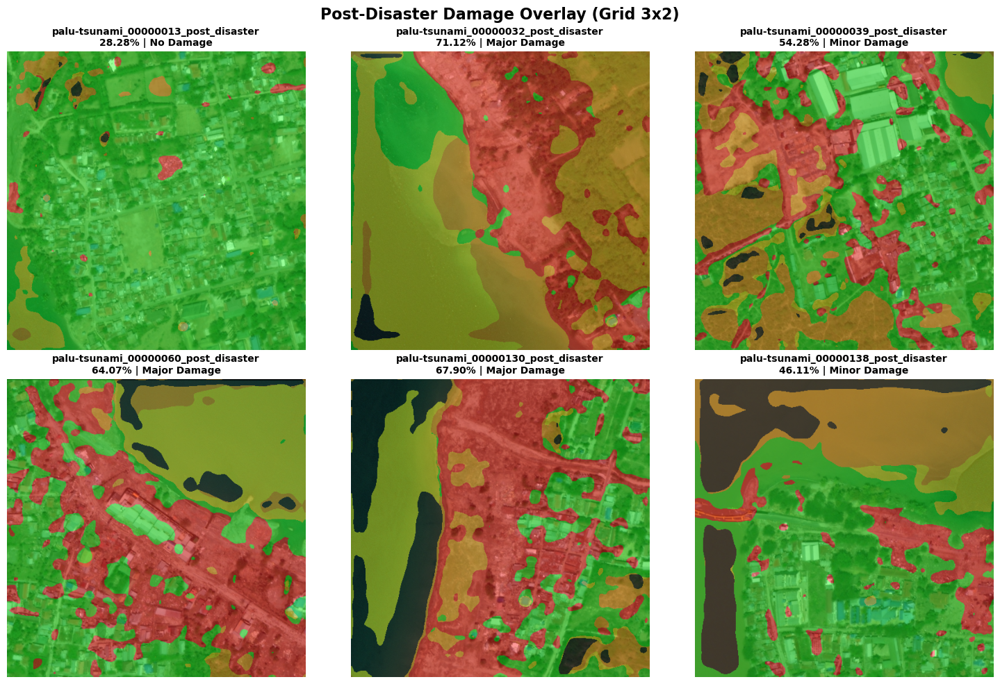

✓ Overlay palu-tsunami_00000013_post_disaster: 28.28% - No Damage
✓ Overlay palu-tsunami_00000032_post_disaster: 71.12% - Major Damage
✓ Overlay palu-tsunami_00000039_post_disaster: 54.28% - Minor Damage
✓ Overlay palu-tsunami_00000060_post_disaster: 64.07% - Major Damage
✓ Overlay palu-tsunami_00000130_post_disaster: 67.90% - Major Damage
✓ Overlay palu-tsunami_00000138_post_disaster: 46.11% - Minor Damage


In [44]:
import os
import numpy as np
import matplotlib.pyplot as plt
from glob import glob
from PIL import Image
import torch

if 'model' not in globals() or 'device' not in globals():
    raise RuntimeError("Jalankan Cell 1-3 terlebih dulu agar model dan device tersedia.")
if 'mask_to_rgb' not in globals() or 'calc_damage_score' not in globals() or 'classify_damage' not in globals():
    raise RuntimeError("Jalankan Cell 5 terlebih dulu agar fungsi visualisasi tersedia.")

if 'PRED_DIR' not in globals():
    PRED_DIR = "predictions"
os.makedirs(PRED_DIR, exist_ok=True)

def _resolve_pre_post_paths(img_path):
    img_path = os.path.normpath(img_path)

    if "post-disaster" in img_path:
        post_path = img_path
        pre_dir = os.path.dirname(img_path).replace("post-disaster", "pre-disaster")
        pre_name = os.path.basename(img_path).replace("_post_disaster", "_pre_disaster")
        pre_path = os.path.join(pre_dir, pre_name)
    elif "pre-disaster" in img_path:
        pre_path = img_path
        post_dir = os.path.dirname(img_path).replace("pre-disaster", "post-disaster")
        post_name = os.path.basename(img_path).replace("_pre_disaster", "_post_disaster")
        post_path = os.path.join(post_dir, post_name)
    else:
        raise ValueError("img_path harus berada di folder pre-disaster atau post-disaster")

    if not os.path.exists(pre_path):
        raise FileNotFoundError(f"Pre image tidak ditemukan: {pre_path}")
    if not os.path.exists(post_path):
        raise FileNotFoundError(f"Post image tidak ditemukan: {post_path}")

    return pre_path, post_path

def _predict_overlay_data(img_path):
    pre_path, post_path = _resolve_pre_post_paths(img_path)

    pre_img = Image.open(pre_path).convert('RGB').resize((512, 512), Image.BILINEAR)
    post_img = Image.open(post_path).convert('RGB').resize((512, 512), Image.BILINEAR)

    pre_np = np.asarray(pre_img, dtype=np.float32) / 255.0
    post_np = np.asarray(post_img, dtype=np.float32) / 255.0

    image_6ch = np.concatenate([pre_np, post_np], axis=2)
    image_6ch = np.transpose(image_6ch, (2, 0, 1))
    image_tensor = torch.from_numpy(image_6ch).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(image_tensor)
        pred_mask = torch.argmax(output, dim=1)[0].cpu().numpy()

    score = calc_damage_score(pred_mask)
    damage_class = classify_damage(score)
    mask_rgb = mask_to_rgb(pred_mask)
    image_id = os.path.splitext(os.path.basename(post_path))[0]

    return {
        'image_id': image_id,
        'post_path': post_path,
        'post_img': np.asarray(post_img),
        'mask_rgb': mask_rgb,
        'damage_score': score,
        'damage_percentage': f"{score*100:.2f}%",
        'damage_class': damage_class
    }

OVERLAY_DIR = os.path.join(PRED_DIR, "overlay")
os.makedirs(OVERLAY_DIR, exist_ok=True)

sample_post_paths = sorted(glob("sample_image/post-disaster/*"))[:8]
overlay_results = [_predict_overlay_data(p) for p in sample_post_paths]

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.flatten()

for i, ax in enumerate(axes):
    if i < len(overlay_results):
        r = overlay_results[i]
        ax.imshow(r['post_img'])
        ax.imshow(r['mask_rgb'], alpha=0.40)
        ax.set_title(f"{r['image_id']}\n{r['damage_percentage']} | {r['damage_class']}", fontsize=10, fontweight='bold')
        ax.axis('off')

        save_path = os.path.join(OVERLAY_DIR, f"{r['image_id']}_overlay.png")
        plt.imsave(save_path, r['post_img'])
    else:
        ax.axis('off')

plt.suptitle("Post-Disaster Damage Overlay (Grid 3x2)", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

for r in overlay_results:
    print(f"✓ Overlay {r['image_id']}: {r['damage_percentage']} - {r['damage_class']}")